# ITI Lick Models

Two logistic regression models predicting spontaneous (inter-trial-interval) lick train starts:

- **Model 1** — scalar features: time since last lick/reward/go-cue/switch, time in session, time until next switch  
- **Model 2** — temporal GLM: lagged binary event regressors (5 event types × *n_lags*) + continuous time-in-session

**Cell order**
1. Imports & paths  
2. Choose an example session  
3. Visualise events in a 1-minute window  
4. Trial timeline — go cues + cut-off bars  
5. Define session list for model fitting  
6. Prepare & concatenate data across sessions  
7. Fit Model 1 (all sessions combined)  
8. Fit Model 2 (all sessions combined)  
9. Visualise model results

## 1. Imports & paths

In [17]:
import os
import pathlib
import sys

try:
    _here = pathlib.Path(__file__).resolve().parent
except NameError:
    try:
        _here = pathlib.Path(__vsc_ipynb_file__).resolve().parent
    except NameError:
        _here = pathlib.Path(os.getcwd())

_beh_ephys_root = str((_here / '../..').resolve())
if _beh_ephys_root not in sys.path:
    sys.path.insert(0, _beh_ephys_root)

# add figure_preparation to path so we can import iti_lick_models
_fig_prep = str((_here / '../figure_preparation').resolve())
if _fig_prep not in sys.path:
    sys.path.insert(0, _fig_prep)

import json
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import statsmodels.api as sm
from joblib import Parallel, delayed
from scipy.stats import zscore

from utils.beh_functions import get_session_tbl
from utils.lick_utils import load_licks, load_licks_video
from utils.capsule_migration import CAPSULE_ROOT, capsule_directories
from utils.combine_tools import apply_qc
from iti_lick_models import (
    prepare_iti_lick_data,
    fit_model1,
    fit_model2,
    _build_design_matrix,
    plot_model1_coefficients,
    plot_model2_kernels,
)

warnings.filterwarnings('ignore')
%matplotlib inline

capsule_dirs  = capsule_directories()
target_folder = os.path.join(capsule_dirs['manuscript_fig_dir'], 'F_iti_lick')
os.makedirs(target_folder, exist_ok=True)
print('Output →', target_folder)

Output → /root/capsule/scratch/result/manuscript/figures/F_iti_lick


## 2. Choose an example session

In [18]:
# ── pick any session from the QC-filtered list, or hardcode one here ─────────
EXAMPLE_SESSION = 'behavior_751769_2025-01-18_10-15-25'
BIN_SIZE = 1   # seconds
VIDEO    = False  # set True to use video-tracked licks when available

print('Preparing data for', EXAMPLE_SESSION, '…')
data_ex = prepare_iti_lick_data(EXAMPLE_SESSION, bin_size=BIN_SIZE, video=VIDEO)
print(f'  {data_ex["iti_mask"].sum()} valid ITI bins  |  '
      f'{data_ex["y"][data_ex["iti_mask"]].sum()} lick-train starts in ITI')

Preparing data for behavior_751769_2025-01-18_10-15-25 …
  1159 valid ITI bins  |  26 lick-train starts in ITI


## 3. Visualise events in a 1-minute window

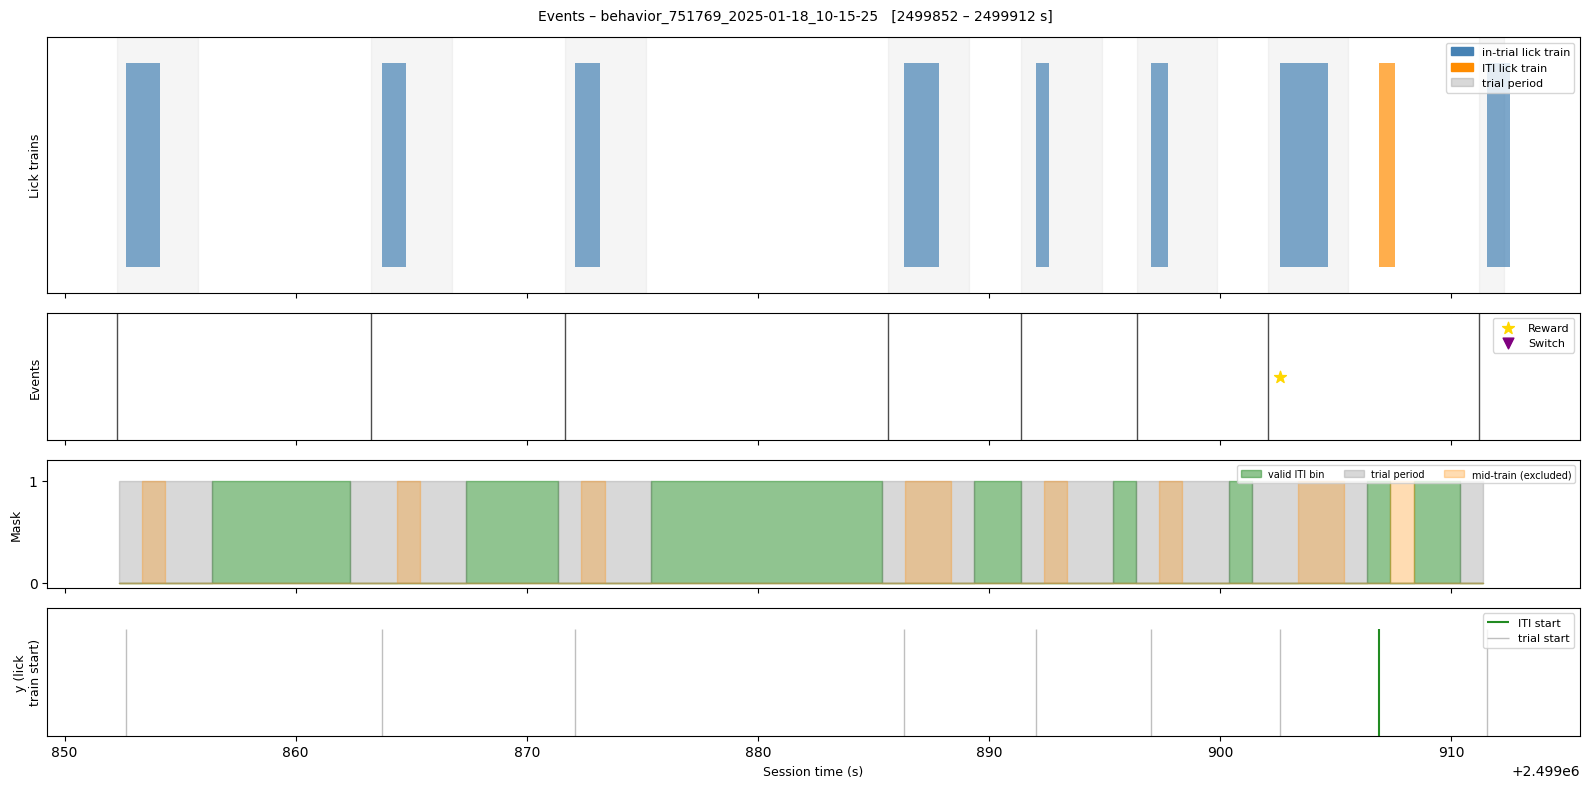

In [19]:
# ── choose a 60-second window starting from an early trial ───────────────────
sess_tbl    = data_ex['session_tbl']
lick_trains = data_ex['lick_trains']
bins        = data_ex['bins']
t0_win      = sess_tbl['goCue_start_time'].values[2]   # start of window
t1_win      = t0_win + 60.0

# helper: events in window
def _win(arr): return arr[(arr >= t0_win) & (arr < t1_win)]

go_cues_win    = _win(sess_tbl['goCue_start_time'].values)
rewarded       = (sess_tbl['rewarded_historyL'] | sess_tbl['rewarded_historyR']).values
reward_times   = sess_tbl.loc[rewarded, 'reward_outcome_time'].values
reward_times_w = _win(reward_times)

# switch choices
from iti_lick_models import _switch_mask
sw_mask        = _switch_mask(sess_tbl)
switch_times_w = _win(sess_tbl['goCue_start_time'].values[sw_mask])

# lick trains in window
ts_all       = lick_trains['train_starts']
te_all       = lick_trains['train_ends']
in_trial_all = lick_trains['in_trial']
win_idx  = (ts_all >= t0_win) & (ts_all < t1_win)
ts_win   = ts_all[win_idx]
te_win   = te_all[win_idx]
in_win   = in_trial_all[win_idx]

# ITI mask in window (bin-level, used only for row 2)
bin_in_win = (bins >= t0_win) & (bins < t1_win)
bins_win   = bins[bin_in_win]
iti_win    = data_ex['iti_mask'][bin_in_win]
trial_win  = data_ex['trial_mask'][bin_in_win]
mid_win    = data_ex['mid_train_mask'][bin_in_win]

# Exact trial cut-off times (same logic as prepare_iti_lick_data) for shading
trial_spans = []  # list of (gc, trial_end) for trials overlapping the window
for gc in sess_tbl['goCue_start_time'].values:
    if gc > t1_win:
        break
    tend = gc + 3.5
    trial_lick_ends = te_all[(ts_all >= gc) & (ts_all <= gc + 3.5)]
    if len(trial_lick_ends) > 0:
        tend = max(tend, float(np.max(trial_lick_ends)))
    if tend >= t0_win:   # only keep spans that overlap the window
        trial_spans.append((max(gc, t0_win), min(tend, t1_win)))

# ── figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(16, 8), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1, 1, 1]})

# — row 0: lick trains as coloured boxes ——————————————————————————————————
ax = axes[0]
# trial-period shading from exact times
for gc, tend in trial_spans:
    ax.axvspan(gc, tend, alpha=0.08, color='gray', zorder=0)
for ts, te, intrial in zip(ts_win, te_win, in_win):
    color = 'steelblue' if intrial else 'darkorange'
    ax.axvspan(ts, te, ymin=0.1, ymax=0.9, alpha=0.7, color=color, linewidth=0)
ax.set_yticks([])
ax.set_ylabel('Lick trains', fontsize=9)
blue_p  = mpatches.Patch(color='steelblue',  label='in-trial lick train')
oran_p  = mpatches.Patch(color='darkorange', label='ITI lick train')
gray_p  = mpatches.Patch(color='gray',       alpha=0.3, label='trial period')
ax.legend(handles=[blue_p, oran_p, gray_p], fontsize=8, loc='upper right')

# — row 1: go cues & rewards ——————————————————————————————————————————————
ax = axes[1]
for gc in go_cues_win:
    ax.axvline(gc, color='k', linewidth=1, alpha=0.7)
ax.scatter(reward_times_w, np.ones_like(reward_times_w) * 0.5,
           marker='*', s=80, color='gold', zorder=5, label='Reward')
ax.scatter(switch_times_w, np.ones_like(switch_times_w) * 0.2,
           marker='v', s=60, color='purple', zorder=5, label='Switch')
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_ylabel('Events', fontsize=9)
ax.legend(fontsize=8, loc='upper right')

# — row 2: valid ITI mask ——————————————————————————————————————————————————
ax = axes[2]
ax.fill_between(bins_win, iti_win.astype(float), step='post',
                alpha=0.5, color='forestgreen', label='valid ITI bin')
ax.fill_between(bins_win, trial_win.astype(float), step='post',
                alpha=0.3, color='gray', label='trial period')
ax.fill_between(bins_win, mid_win.astype(float), step='post',
                alpha=0.3, color='darkorange', label='mid-train (excluded)')
ax.set_ylim(-0.05, 1.2)
ax.set_yticks([0, 1])
ax.set_ylabel('Mask', fontsize=9)
ax.legend(fontsize=7, loc='upper right', ncol=3)

# — row 3: lick-train starts at actual times (aligns exactly with row 0) ———
ax = axes[3]
ax.vlines(ts_win[~in_win], 0, 1, color='forestgreen', linewidth=1.5, label='ITI start')
ax.vlines(ts_win[ in_win], 0, 1, color='gray',        linewidth=1.0, alpha=0.5, label='trial start')
ax.set_ylim(0, 1.2)
ax.set_yticks([])
ax.set_ylabel('y (lick\ntrain start)', fontsize=9)
ax.set_xlabel('Session time (s)', fontsize=9)
ax.legend(fontsize=8, loc='upper right')

fig.suptitle(f'Events – {EXAMPLE_SESSION}   [{t0_win:.0f} – {t1_win:.0f} s]', fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join(target_folder, f'{EXAMPLE_SESSION}_event_viz.pdf'), bbox_inches='tight')
plt.show()

## 4. Trial timeline — go cues + cut-off bars

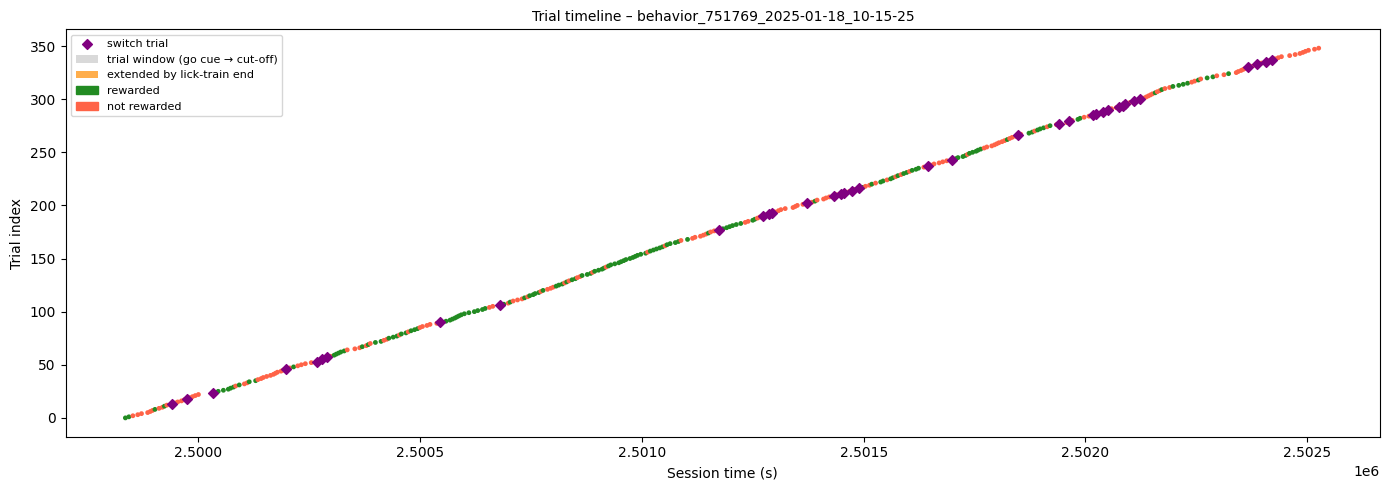

In [20]:
# ── for every trial: mark go cue and the bin-level trial cut-off ─────────────
go_cues    = sess_tbl['goCue_start_time'].values
ts_all_s   = lick_trains['train_starts']
te_all_s   = lick_trains['train_ends']

# compute per-trial trial_end exactly as prepare_iti_lick_data does
trial_ends = []
for gc in go_cues:
    tend = gc + 3.5
    trial_lick_ends = te_all_s[(ts_all_s >= gc) & (ts_all_s <= gc + 3.5)]
    if len(trial_lick_ends) > 0:
        tend = max(tend, float(np.max(trial_lick_ends)))
    trial_ends.append(tend)
trial_ends = np.array(trial_ends)
trial_durations = trial_ends - go_cues

rewarded_trial = rewarded  # boolean array, len == n_trials

fig, ax = plt.subplots(figsize=(14, 5))

n_trials = len(go_cues)
trial_idx = np.arange(n_trials)

# colour by reward
c_rwd  = np.where(rewarded_trial, 'forestgreen', 'tomato')

# go-cue dots
ax.scatter(go_cues, trial_idx, c=c_rwd, s=12, zorder=4, linewidths=0)

# horizontal bars: length = trial duration (grey)
ax.barh(trial_idx, trial_durations, left=go_cues,
        height=0.6, color='silver', alpha=0.6, zorder=2,
        label='trial window (go cue → cut-off)')

# mark default 3.5 s horizon
ax.axvline(go_cues[0] + 3.5, color='dimgray', linewidth=0.5, linestyle='--', alpha=0.0)

# extended bar segments in orange (extended beyond 3.5 s)
extended = trial_durations > 3.51
ax.barh(trial_idx[extended],
        trial_durations[extended] - 3.5,
        left=go_cues[extended] + 3.5,
        height=0.6, color='darkorange', alpha=0.7, zorder=3,
        label='extended by lick-train end')

# switch-trial markers
sw_trial_idx = np.where(sw_mask)[0]
ax.scatter(go_cues[sw_trial_idx], sw_trial_idx,
           marker='D', s=25, color='purple', zorder=5, label='switch trial')

ax.set_xlabel('Session time (s)', fontsize=10)
ax.set_ylabel('Trial index', fontsize=10)
ax.set_title(f'Trial timeline – {EXAMPLE_SESSION}', fontsize=10)

rwd_p  = mpatches.Patch(color='forestgreen', label='rewarded')
nrwd_p = mpatches.Patch(color='tomato',      label='not rewarded')
ax.legend(handles=ax.get_legend_handles_labels()[0] + [rwd_p, nrwd_p],
          labels =ax.get_legend_handles_labels()[1] + ['rewarded', 'not rewarded'],
          fontsize=8, loc='upper left')

plt.tight_layout()
fig.savefig(os.path.join(target_folder, f'{EXAMPLE_SESSION}_trial_timeline.pdf'), bbox_inches='tight')
plt.show()

## 5. Session list for model fitting

Same QC pipeline as `F_behavior_w_FP.ipynb`: load `combined_beh_sessions.pkl`,
apply the `beh_only` quality constraints, then take the filtered session list.

In [21]:
# ── load combined session table (same file as F_behavior_w_FP.ipynb) ─────────
pickle_file = os.path.join(
    capsule_dirs['manuscript_fig_prep_dir'],
    'combined_session_tbl', 'combined_beh_sessions.pkl'
)
with open(pickle_file, 'rb') as fh:
    combined_session_tbl = pickle.load(fh)

# ── apply behavioural QC (same criteria as F_behavior_w_FP.ipynb) ─────────────
beh_criteria_file = os.path.join(
    CAPSULE_ROOT,
    'code/beh_ephys_analysis/session_combine/metrics/beh_only.json'
)
with open(beh_criteria_file) as fh:
    beh_constraints = json.load(fh)

combined_session_tbl_filtered, combined_session_tbl, _fig_qc, _ = apply_qc(
    combined_session_tbl, beh_constraints
)
plt.close(_fig_qc)

session_list = combined_session_tbl_filtered['session'].to_list()
print(f'{len(session_list)} sessions after QC  '
      f'({len(combined_session_tbl)} total before filtering)')

Applying bounds for session_len: [90, None]
 - session_len: 345 -> 344 units passed
Applying bounds for p_sw_L: [0.04, None]
 - p_sw_L: 344 -> 341 units passed
Applying bounds for aN: [0.15, None]
 - aN: 341 -> 278 units passed
Applying bounds for diff_1: [0, None]
 - diff_1: 278 -> 277 units passed
Applying bounds for bias: [-1.25, 1.25]
 - bias: 277 -> 259 units passed
Number of opto rows after filtering: 259
Number of non-opto rows after filtering: 259
259 sessions after QC  (345 total before filtering)


## 6. Prepare & concatenate data across sessions

In [22]:
BIN_SIZE_FIT = 2   # seconds per bin
N_LAGS       = 20    # Model 2 lags (= 5 s at 100 ms bins)
N_JOBS       = -1    # parallel workers (-1 = all cores)
VIDEO_FIT    = False

def _prep_one(sess):
    try:
        d = prepare_iti_lick_data(sess, bin_size=BIN_SIZE_FIT, video=VIDEO_FIT)
        if d is None:
            return None
        n_iti = d['iti_mask'].sum()
        n_starts = d['y'][d['iti_mask']].sum()
        if n_iti < 100 or n_starts < 5:
            print(f'  skip {sess}: only {n_iti} ITI bins / {n_starts} starts')
            return None
        return d
    except Exception as e:
        print(f'  error {sess}: {e}')
        return None

print('Preparing sessions …')
all_data = Parallel(n_jobs=N_JOBS, backend='loky', verbose=5)(
    delayed(_prep_one)(s) for s in session_list
)
all_data   = [d for d in all_data if d is not None]
valid_sess = [d['session_tbl']['goCue_start_time'].iloc[0] for d in all_data]   # just for bookkeeping
print(f'\n{len(all_data)}/{len(session_list)} sessions passed QC')

Preparing sessions …


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.


  skip behavior_781166_2025-05-16_14-16-34: only 549 ITI bins / 3 starts


[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:  1.3min


  skip behavior_ZS061_2021-04-22_16-25-00: only 436 ITI bins / 4 starts
  skip behavior_ZS061_2021-04-30_17-06-18: only 471 ITI bins / 3 starts
  skip behavior_ZS061_2021-05-01_18-28-14: only 433 ITI bins / 3 starts


[Parallel(n_jobs=-1)]: Done 130 tasks      | elapsed:  2.5min



255/259 sessions passed QC


[Parallel(n_jobs=-1)]: Done 259 out of 259 | elapsed:  3.9min finished


In [ ]:
# ── concatenate y and scalar features (Model 1) ───────────────────────────────
M1_FEATURES = [
    'time_since_train_end',
    'time_since_reward',
    'time_in_session',
    'time_since_switch',
    'time_until_switch',
    'time_since_gocue',
]

y_cat    = np.concatenate([d['y'][d['iti_mask']]            for d in all_data])
feat_cat = {
    f: np.concatenate([d['scalar_features'][f][d['iti_mask']] for d in all_data])
    for f in M1_FEATURES
}

# ── concatenate y and design matrices (Model 2) ───────────────────────────────
X_parts     = []
y_parts_all = []   # all lick-train starts in ITI
y_parts_out = []   # only out-of-trial lick-train starts in ITI

for d in all_data:
    X_sess, feat_names = _build_design_matrix(d['event_vectors'], N_LAGS, d['iti_mask'])
    X_parts.append(X_sess)

    # y_all: every lick-train start (in-trial flag already excluded via iti_mask)
    y_parts_all.append(d['y'][d['iti_mask']].astype(float))

    # y_out: only lick-train starts that are NOT in-trial
    lt = d['lick_trains']
    starts_out = lt['train_starts'][~lt['in_trial']]
    n_bins = len(d['bins'])
    y_out = np.zeros(n_bins, dtype=np.int8)
    if len(starts_out) > 0:
        bidx = np.clip(
            ((starts_out - d['t_start']) / d['bin_size']).astype(int),
            0, n_bins - 1
        )
        y_out[bidx] = 1
    y_parts_out.append(y_out[d['iti_mask']].astype(float))

X_cat_m2    = np.vstack(X_parts)
y_cat_m2    = np.concatenate(y_parts_all)   # all starts
y_cat_m2_out = np.concatenate(y_parts_out)  # out-of-trial starts only

print(f'Model 1  — {len(y_cat)} bins  |  {int(y_cat.sum())} starts  |  base rate {y_cat.mean():.4f}')
print(f'Model 2a — {int(y_cat_m2.sum())} starts (all)           |  base rate {y_cat_m2.mean():.4f}')
print(f'Model 2b — {int(y_cat_m2_out.sum())} starts (out-of-trial)  |  base rate {y_cat_m2_out.mean():.4f}')
print(f'X shape  — {X_cat_m2.shape}')

## 7. Fit Model 1 (all sessions combined)

In [24]:
import pandas as pd

X_m1_df  = pd.DataFrame(feat_cat)
valid_m1 = X_m1_df.notna().all(axis=1).values
X_m1_z   = X_m1_df[valid_m1].apply(lambda c: zscore(c, nan_policy='omit'))
y_m1     = y_cat[valid_m1].astype(float)

X_m1_sm  = sm.add_constant(X_m1_z)
glm_m1   = sm.GLM(y_m1, X_m1_sm,
                  family=sm.families.Binomial(link=sm.families.links.Logit()))
result_m1 = glm_m1.fit()
print(result_m1.summary2())

                  Results: Generalized linear model
Model:                GLM               AIC:             92376.1287   
Link Function:        Logit             BIC:             -1295298.6328
Dependent Variable:   y                 Log-Likelihood:  -46181.      
Date:                 2026-10-30 00:43  LL-Null:         -48168.      
No. Observations:     118744            Deviance:        92111.       
Df Model:             6                 Pearson chi2:    1.36e+16     
Df Residuals:         118737            Scale:           1.0000       
Method:               IRLS                                            
----------------------------------------------------------------------
                      Coef.  Std.Err.     z     P>|z|   [0.025  0.975]
----------------------------------------------------------------------
const                -2.4251   0.0184 -131.8248 0.0000 -2.4612 -2.3891
time_since_train_end -4.5513   0.1107  -41.0990 0.0000 -4.7683 -4.3342
time_since_reward    -0.2

In [25]:
# ── Model 1 extension: split time_since_train_end into in-trial vs out-of-trial ──
M1_EXT_FEATURES = [
    'time_since_out_trial_train_end',
    'time_since_reward',
    'time_in_session',
    'time_since_switch',
    'time_until_switch',
    'time_since_gocue',
]
feat_cat_ext = {
    f: np.concatenate([d['scalar_features'][f][d['iti_mask']] for d in all_data])
    for f in M1_EXT_FEATURES
}
X_m1_ext_df = pd.DataFrame(feat_cat_ext)
valid_ext   = X_m1_ext_df.notna().all(axis=1).values
X_m1_ext_z  = X_m1_ext_df[valid_ext].apply(lambda c: zscore(c, nan_policy='omit'))
y_m1_ext    = y_cat[valid_ext].astype(float)

X_m1_ext_sm  = sm.add_constant(X_m1_ext_z)
glm_m1_ext   = sm.GLM(y_m1_ext, X_m1_ext_sm,
                      family=sm.families.Binomial(link=sm.families.links.Logit()))
result_m1_ext = glm_m1_ext.fit()
print(result_m1_ext.summary2())

                       Results: Generalized linear model
Model:                    GLM                  AIC:                89211.3037   
Link Function:            Logit                BIC:                -1289131.8538
Dependent Variable:       y                    Log-Likelihood:     -44599.      
Date:                     2026-10-30 00:43     LL-Null:            -47993.      
No. Observations:         118028               Deviance:           89197.       
Df Model:                 6                    Pearson chi2:       2.24e+10     
Df Residuals:             118021               Scale:              1.0000       
Method:                   IRLS                                                  
--------------------------------------------------------------------------------
                                Coef.  Std.Err.     z     P>|z|   [0.025  0.975]
--------------------------------------------------------------------------------
const                          -2.2558   0.0141 -159

In [26]:
def _result_to_table(result, skip_const=False):
    """Return a styled DataFrame from a statsmodels GLM result."""
    params = result.params
    bse    = result.bse
    zvals  = result.tvalues
    pvals  = result.pvalues
    ci     = result.conf_int()

    rows = []
    for name in params.index:
        if skip_const and name == 'const':
            continue
        p = pvals[name]
        rows.append({
            'Feature':   name,
            'Coef.':     params[name],
            'Std. Err.': bse[name],
            'z':         zvals[name],
            'P>|z|':     p,
            '[0.025':    ci.loc[name, 0],
            '0.975]':    ci.loc[name, 1],
            'sig':       '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else '')),
        })

    df = pd.DataFrame(rows).set_index('Feature')

    def _color_sig(row):
        if row['P>|z|'] < 0.001:
            bg = '#ffd6d6'
        elif row['P>|z|'] < 0.05:
            bg = '#fff3cd'
        else:
            bg = ''
        return [f'background-color: {bg}'] * len(row)

    fmt = {
        'Coef.':     '{:.4f}',
        'Std. Err.': '{:.4f}',
        'z':         '{:.3f}',
        'P>|z|':     '{:.4f}',
        '[0.025':    '{:.4f}',
        '0.975]':    '{:.4f}',
    }
    return df.style.apply(_color_sig, axis=1).format(fmt)

_result_to_table(result_m1_ext, skip_const=True)

,Coef.,Std. Err.,z,P>|z|,[0.025,0.975],sig
Feature,,,,,,,
time_since_out_trial_train_end,-1.4210,0.0276,-51.520,0.0000,-1.4750,-1.3669,***
time_since_reward,-0.4659,0.0320,-14.557,0.0000,-0.5287,-0.4032,***
time_in_session,-0.0626,0.0092,-6.807,0.0000,-0.0806,-0.0446,***
time_since_switch,-0.0278,0.0090,-3.097,0.0020,-0.0454,-0.0102,**
time_until_switch,0.0248,0.0086,2.875,0.0040,0.0079,0.0418,**
time_since_gocue,-0.2933,0.0186,-15.734,0.0000,-0.3298,-0.2567,***


In [27]:
def _result_to_df(result, skip_const=True):
    ci = result.conf_int()
    rows = []
    for name in result.params.index:
        if skip_const and name == 'const':
            continue
        p = result.pvalues[name]
        rows.append({
            'feature':   name,
            'coef':      result.params[name],
            'std_err':   result.bse[name],
            'z':         result.tvalues[name],
            'p':         p,
            'ci_lo':     ci.loc[name, 0],
            'ci_hi':     ci.loc[name, 1],
            'sig':       '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else '')),
        })
    return pd.DataFrame(rows)

csv_path = os.path.join(target_folder, 'model1_ext_coefficients.csv')
_result_to_df(result_m1_ext).to_csv(csv_path, index=False)
print('Saved →', csv_path)

Saved → /root/capsule/scratch/result/manuscript/figures/F_iti_lick/model1_ext_coefficients.csv


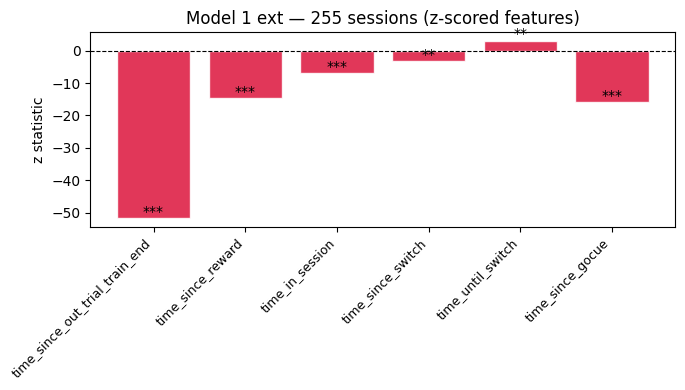

In [28]:
# ── Model 1 ext: z-statistic bar chart ───────────────────────────────────────
coefs  = result_m1_ext.tvalues[1:]
pvals  = result_m1_ext.pvalues[1:]
colors = ['crimson' if p < 0.05 else 'lightgray' for p in pvals]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(coefs))
ax.bar(x, coefs.values, color=colors, alpha=0.85, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(coefs.index, rotation=45, ha='right', fontsize=9)
ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
ax.set_ylabel('z statistic')
ax.set_title(f'Model 1 ext — {len(all_data)} sessions (z-scored features)')

for xi, (z, p) in enumerate(zip(coefs.values, pvals)):
    label = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
    if label:
        ax.text(xi, z + (0.15 if z >= 0 else -0.4), label,
                ha='center', va='bottom', fontsize=10, color='k')

plt.tight_layout()
fig.savefig(os.path.join(target_folder, 'model1_ext_barplot.pdf'), bbox_inches='tight')
plt.show()

## 8. Fit Model 2 (temporal GLM, all sessions combined)

In [ ]:
X_m2_sm = sm.add_constant(X_cat_m2)

# Model 2a: predict all lick-train starts in ITI
glm_m2a   = sm.GLM(y_cat_m2,     X_m2_sm,
                   family=sm.families.Binomial(link=sm.families.links.Logit()))
result_m2a = glm_m2a.fit(maxiter=200, disp=False)
print(f'Model 2a converged: {result_m2a.converged}  |  '
      f'pseudo-R² = {result_m2a.pseudo_rsquared(kind="cs"):.4f}')

# Model 2b: predict only out-of-trial lick-train starts
glm_m2b   = sm.GLM(y_cat_m2_out, X_m2_sm,
                   family=sm.families.Binomial(link=sm.families.links.Logit()))
result_m2b = glm_m2b.fit(maxiter=200, disp=False)
print(f'Model 2b converged: {result_m2b.converged}  |  '
      f'pseudo-R² = {result_m2b.pseudo_rsquared(kind="cs"):.4f}')

In [ ]:
# ── Model 2a & 2b: temporal kernels side by side ─────────────────────────────
event_keys = ['train_start', 'reward', 'switch', 'gocue', 'train_end']
colors_m2  = dict(train_start='steelblue', reward='forestgreen',
                  switch='darkorchid',      gocue='darkorange',
                  train_end='teal')
labels_m2  = dict(train_start='Lick train start', reward='Reward',
                  switch='Switch choice',          gocue='Go cue',
                  train_end='Lick train end')

model_specs = [
    (result_m2a, 'Model 2a — all ITI lick-train starts'),
    (result_m2b, 'Model 2b — out-of-trial starts only'),
]

lag_times = np.arange(1, N_LAGS + 1) * BIN_SIZE_FIT
n_cols    = len(event_keys)
n_rows    = len(model_specs)

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4.5 * n_cols, 4 * n_rows),
                         sharey='row', sharex=True)

for row, (result, row_title) in enumerate(model_specs):
    params = np.asarray(result.params[1:])
    ci     = np.asarray(result.conf_int()[1:])
    pvals  = np.asarray(result.pvalues[1:])

    for col, key in enumerate(event_keys):
        i0    = col * N_LAGS
        i1    = i0 + N_LAGS
        coefs = params[i0:i1]
        lo    = ci[i0:i1, 0]
        hi    = ci[i0:i1, 1]
        pv    = pvals[i0:i1]

        ax = axes[row, col]
        ax.plot(lag_times, coefs, color=colors_m2[key], linewidth=2)
        ax.fill_between(lag_times, lo, hi, alpha=0.25, color=colors_m2[key])
        sig = pv < 0.05
        ax.scatter(lag_times[sig], coefs[sig], color=colors_m2[key], s=20, zorder=4)
        ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
        ax.set_xlabel('Time before licking (s)', fontsize=9)
        if col == 0:
            ax.set_ylabel(f'{row_title}\nβ coefficient', fontsize=8)
        if row == 0:
            ax.set_title(labels_m2[key], fontsize=10)

plt.tight_layout()
fig.savefig(os.path.join(target_folder, 'model2_kernels.pdf'), bbox_inches='tight')
plt.show()

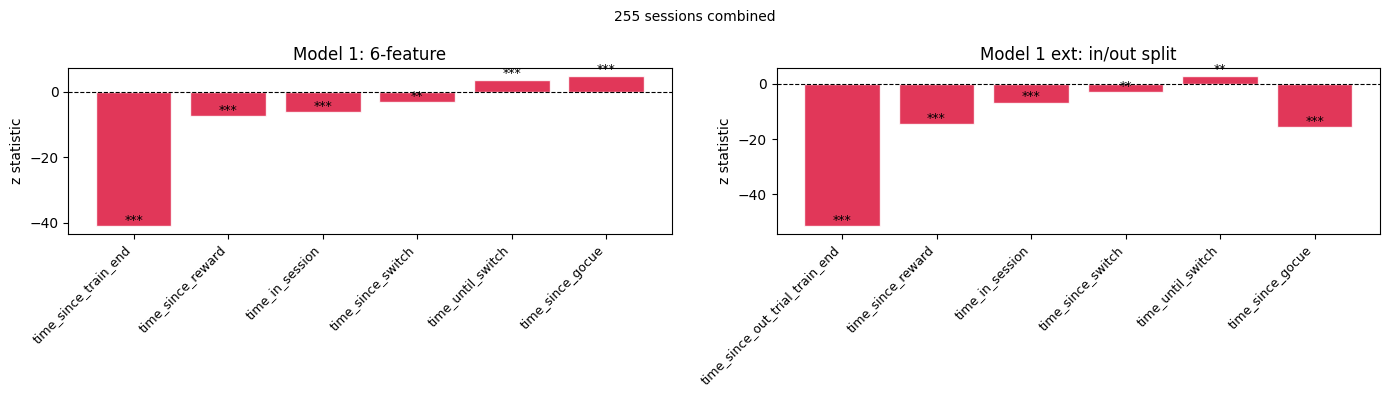

In [34]:
# ── Model 1: z-statistic bar chart ───────────────────────────────────────────
def _bar_coefs(result, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    else:
        fig = ax.figure
    coefs  = result.tvalues[1:]
    pvals  = result.pvalues[1:]
    colors = ['crimson' if p < 0.05 else 'lightgray' for p in pvals]
    x = np.arange(len(coefs))
    ax.bar(x, coefs.values, color=colors, alpha=0.85, edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(coefs.index, rotation=45, ha='right', fontsize=9)
    ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
    ax.set_ylabel('z statistic')
    ax.set_title(title)
    # annotate p-values
    for xi, (z, p) in enumerate(zip(coefs.values, pvals)):
        if p < 0.001:
            label = '***'
        elif p < 0.01:
            label = '**'
        elif p < 0.05:
            label = '*'
        else:
            label = ''
        if label:
            ax.text(xi, z + (0.1 if z >= 0 else -0.3), label,
                    ha='center', va='bottom', fontsize=9, color='k')
    return fig

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
_bar_coefs(result_m1,     'Model 1: 6-feature', axes[0])
_bar_coefs(result_m1_ext, 'Model 1 ext: in/out split', axes[1])
plt.suptitle(f'{len(all_data)} sessions combined', fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join(target_folder, 'model1_coefficients.pdf'), bbox_inches='tight')
plt.show()

In [ ]:
# ── time-in-session coefficient from Model 2a and 2b ─────────────────────────
ts_idx = len(event_keys) * N_LAGS   # index of the time_in_session column
for label, result in [('2a (all)', result_m2a), ('2b (out-of-trial)', result_m2b)]:
    coef = result.params[1 + ts_idx]
    ci   = result.conf_int().values[ts_idx]
    pval = result.pvalues[1 + ts_idx]
    print(f'Model {label}  time_in_session  β={coef:.4f}  '
          f'95%CI [{ci[0]:.4f}, {ci[1]:.4f}]  p={pval:.4g}')

In [36]:
# ── summary: Model 1 coefficients table ──────────────────────────────────────
summary_rows = []
for name, z, p, ci_lo, ci_hi in zip(
        result_m1.model.exog_names[1:],
        result_m1.tvalues[1:],
        result_m1.pvalues[1:],
        result_m1.conf_int().values[1:, 0],
        result_m1.conf_int().values[1:, 1]):
    summary_rows.append(dict(feature=name, z=z, p=p, ci_lo=ci_lo, ci_hi=ci_hi))
pd.DataFrame(summary_rows).round(4)

,feature,z,p,ci_lo,ci_hi
0,time_since_train_end,-41.0990,0.0000,-4.7683,-4.3342
1,time_since_reward,-7.2169,0.0000,-0.2868,-0.1643
2,time_in_session,-6.1270,0.0000,-0.0741,-0.0382
3,time_since_switch,-3.0845,0.0020,-0.0448,-0.0100
4,time_until_switch,3.5164,0.0004,0.0134,0.0470
5,time_since_gocue,4.9331,0.0000,0.0325,0.0754
